# 🎓 Semester at the study office · starter notebook

**The situation.** About one first-year student in five leaves the university during the first semester. Many of
them could have been helped: a conversation with an adviser, a study group, help with money. But the study office
has only **three advisers**. At the end of **week 6** they can hold about **40 conversations**.

**Your job:** build a model that helps the office decide *who* to talk to, find out what **mistakes** it makes
(students worried for nothing, students missed), turn it into a **rule** the office can use, and then build a small
**Streamlit app** for the office.

**How to work.** Go through the steps in order. Each ✏️ cell is yours to write. Use the hotel notebook (session 10) as your template: it
does every step for hotel bookings. AI assistants are welcome for the code, but make sure you understand each step:
you will explain it in your video. `GUIDE.md` explains the terms on one page.

*The students are synthetic, but every profile is resampled from a real student (UCI "Predict students' dropout
and academic success", 4,424 students, CC BY 4.0), and the risk of leaving follows a model fitted on the real
outcomes.*

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb

# the data lives on GitHub, so this works in Colab without uploading anything
URL = "https://raw.githubusercontent.com/aaubs/ds-master/main/assignments/study-office/data/"
BASE = "data/" if os.path.exists("data/history_week6.csv") else URL
history = pd.read_csv(BASE + "history_week6.csv")   # past students, with what happened
new = pd.read_csv(BASE + "new_week6.csv")           # this year's students, week 6: what happens is not known yet
print(history.shape, new.shape)
history.head()

(2686, 24) (703, 20)


,student_id,cohort,age,admission_grade,international,first_gen,su_scholarship,fees_owed,moved_from_home,married,...,logins_last3,logins_trend,submitted_share,missed_last3,quiz_mean,weeks_since_login,ects_passed_sem1,deregistration_form_opened,last_login_week,left
0,S230000,2023,19,9.1,0,1,0,0,1,0,...,23.0,-3.67,1.00,0.0,70.83,0.0,6,0,12,0
1,S230001,2023,35,5.2,0,0,0,0,0,0,...,16.0,1.00,0.83,0.0,55.20,0.0,5,0,12,0
2,S230002,2023,18,6.9,0,1,0,0,0,0,...,15.0,-1.67,1.00,0.0,67.33,0.0,8,0,12,0
3,S230003,2023,21,7.2,0,1,0,0,0,0,...,7.0,-1.67,0.33,2.0,70.00,0.0,5,0,12,0
4,S230004,2023,21,7.1,0,1,0,0,1,0,...,15.0,-1.33,0.67,0.0,66.75,0.0,3,0,12,0


---
## 0 · Think first 🤔

Before any code, write down in your own words:

1. **Who decides what?** Who uses the model's output, and what exactly do they decide?
2. **When?** What does the office know about a student at the end of week 6, and what does it not know yet?
3. **The two mistakes.** The model can flag a student who would have stayed anyway (a **false alarm**, a *false
   positive*), or miss a student who then leaves (a **missed student**, a *false negative*). What does each cost,
   and for whom?
4. **Which is worse?** Is one false alarm as bad as one missed student?

*Your answers:*

1. The **study office's advisers** decide whom to invite for a conversation at the end of week 6. The model only
   ranks students by risk; a person decides and talks to them.
2. **Known:** enrolment data (programme, age, grades, grants, fees) and six weeks of platform activity (logins,
   submissions, quizzes). **Not known:** exam results, who will deregister, anything after week 6.
3. **False alarm:** about 500 DKK of adviser time, plus a worried student who may feel labelled or lose confidence.
   **Missed student:** the student loses a year and maybe their plan; the university loses about 60,000 DKK and a study place.
4. A missed student usually costs more, but the harm of a false alarm falls on the student, and it grows if the
   message sounds like a warning. So the rule should limit both, and the message should only ever offer help.

---
## 1 · Look at the data

**`history_week6.csv`**: one row per student from the 2023, 2024 and 2025 cohorts who was still enrolled at the end
of week 6, with what the office knew then, and **`left`** (1 = left later that semester). **`new_week6.csv`**: the
2026 students, this week. This is the list the office has to act on.

| Column | Meaning |
|---|---|
| `age`, `gender`, `programme`, `evening_programme` | from enrolment |
| `admission_grade` | grade point average from upper secondary school (Danish scale) |
| `international`, `first_gen` | international student; first in the family at university |
| `su_scholarship`, `fees_owed`, `moved_from_home`, `married` | money and life situation (0/1) |
| `logins_total`, `logins_last3`, `logins_trend` | logins on the learning platform: weeks 1–6, the last three weeks, and the change |
| `submitted_share`, `missed_last3` | share of weekly assignments handed in; assignments missed in the last three weeks |
| `quiz_mean`, `weeks_since_login` | average quiz score; weeks since the last login |
| `ects_passed_sem1`, `deregistration_form_opened`, `last_login_week` | ⚠️ see step 2 |
| `left` | **the target**: 1 = left later in the semester |

✏️ **Your turn.** How many students leave? Compare the share who left across a few columns you think matter, for example `programme`, `fees_owed`, `submitted_share`. (Template: section 1 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`history['left'].mean()`; `history.groupby('fees_owed')['left'].mean()`; for a number, cut it into groups first: `history.groupby(pd.cut(history['submitted_share'], [0, .5, .8, 1], include_lowest=True))['left'].mean()`.
</details>

In [2]:
print("share who leave:", round(history["left"].mean(), 3))
print(history.groupby("programme")["left"].mean().round(3).sort_values())
print(history.groupby("fees_owed")["left"].mean().round(3))
print(history.groupby(pd.cut(history["submitted_share"], [0, .5, .8, 1], include_lowest=True), observed=True)["left"].mean().round(3))

share who leave: 0.082
programme
Health Science                   0.040
Social Work                      0.046
Tourism                          0.077
Communication & Digital Media    0.085
Learning & Innovation            0.097
Business Administration          0.123
Sustainable Biotechnology        0.160
Software                         0.219
Name: left, dtype: float64
fees_owed
0    0.067
1    0.189
Name: left, dtype: float64
submitted_share
(-0.001, 0.5]    0.213
(0.5, 0.8]       0.098
(0.8, 1.0]       0.047
Name: left, dtype: float64


---
## 2 · What is known when? (leakage)

The model will be used **at the end of week 6**. A column that is only filled in later makes the model look
brilliant here and useless in October. Compare the two files: which columns does the history have that this week's
list does not?

In [3]:
sorted(set(history.columns) - set(new.columns))

['deregistration_form_opened', 'ects_passed_sem1', 'last_login_week', 'left']

✏️ **Your turn.** For each of these columns: when is it recorded? Would the office know it at the end of week 6? Write one sentence each, then make a list `features` of the columns the model may use (not `student_id`, `cohort`, the leaks, or the target). (Template: the leakage hunt, section 3 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

ECTS points are awarded after the exams. A deregistration form is opened by students who are about to leave. The *last* login week is computed over the whole semester. `left` is the target itself.
</details>

In [4]:
leaks = ["ects_passed_sem1", "deregistration_form_opened", "last_login_week"]
features = [c for c in history.columns if c not in ["student_id", "cohort", "left"] + leaks]
print(features)

['age', 'admission_grade', 'international', 'first_gen', 'su_scholarship', 'fees_owed', 'moved_from_home', 'married', 'evening_programme', 'programme', 'gender', 'logins_total', 'logins_last3', 'logins_trend', 'submitted_share', 'missed_last3', 'quiz_mean', 'weeks_since_login']


*Your answer:* `ects_passed_sem1` is recorded after the January exams, months after week 6. `deregistration_form_opened` is
opened by students who are about to leave (82 % of the leavers against 1 % of the others): it *is* the outcome, one
step early. `last_login_week` is the last login of the whole semester, so a leaver's is early by definition. The office
knows none of them at week 6, which is why they are missing from `new_week6.csv`. `left` is the target itself.

---
## 3 · A split by time

The model will be used on **next year's** students, so the split follows time: learn from the 2023 and 2024
cohorts, check on 2025.

✏️ **Your turn.** Make `train` (2023 and 2024) and `val` (2025). How many students are in each, and what share leaves? (Template: section 2 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`train = history[history['cohort'] <= 2024]` and `val = history[history['cohort'] == 2025].copy()`.
</details>

In [5]:
train, val = history[history["cohort"] <= 2024], history[history["cohort"] == 2025].copy()
print(len(train), len(val), round(train["left"].mean(), 3), round(val["left"].mean(), 3))

1749 937 0.088 0.069


---
## 4 · Train a model

Train two models on `train` and compare them on `val` with the **AUC**: pick one student who left and one who
stayed; the AUC is how often the model gives the one who left the higher risk (0.5 = coin flip, 1 = perfect).

1. A **logistic regression**: easy to read. Which features push the risk up or down?
2. **XGBoost**, as in the hotel notebook (session 10). It may not win here, and that is a result, not a failure.

Build both as a pipeline: first prepare the data (fill gaps, scale numbers, one-hot the categories), then the
model. Use the same preparation as the hotel notebook, so you can store the model the same way in step 9.

✏️ **Your turn.** Train the logistic regression, compute its validation AUC, and plot its coefficients.

<details><summary>Hint</summary>

```python
numeric = [c for c in features if c not in ["programme", "gender"]]
categorical = ["programme", "gender"]
prepare = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), categorical)])
logit = make_pipeline(prepare, LogisticRegression(max_iter=2000))
logit.fit(train[features], train["left"])
val["risk"] = logit.predict_proba(val[features])[:, 1]
```
Coefficients: `logit[-1].coef_[0]`, with names from `logit[0].get_feature_names_out()`.
</details>

logistic regression AUC: 0.809


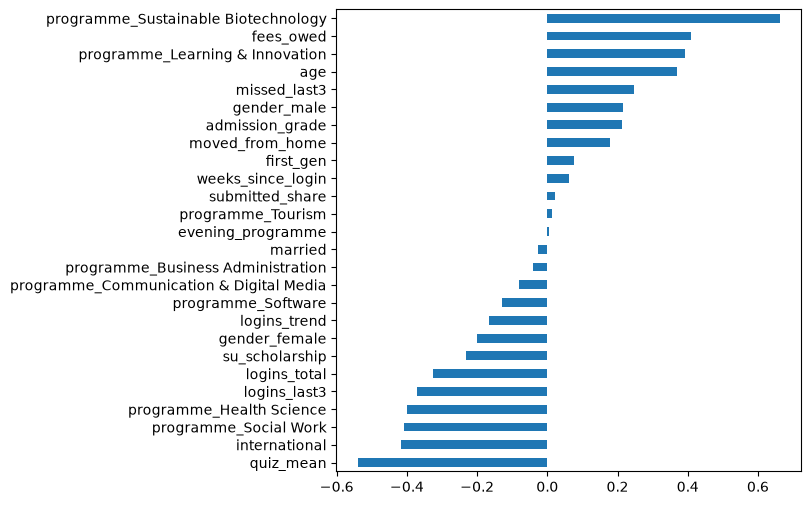

In [6]:
numeric = [c for c in features if c not in ["programme", "gender"]]
categorical = ["programme", "gender"]
def prepare():
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), categorical)])
logit = make_pipeline(prepare(), LogisticRegression(max_iter=2000)).fit(train[features], train["left"])
val["risk_logit"] = logit.predict_proba(val[features])[:, 1]
print("logistic regression AUC:", round(roc_auc_score(val["left"], val["risk_logit"]), 3))
names = [n.split("__", 1)[1] for n in logit[0].get_feature_names_out()]
pd.Series(logit[-1].coef_[0], index=names).sort_values().plot.barh(figsize=(6, 6)); plt.show()

*Your answer:* Logistic regression: AUC ≈ 0.81. Up: owing fees, some programmes (Sustainable Biotechnology, Learning & Innovation),
age, assignments missed in the last three weeks. Down: quiz scores, logins (in total and lately), an SU grant, Health
Science and Social Work. Careful with single coefficients: features that move together (logins, submissions, quizzes)
share the credit, so one of them can get an odd sign (admission grade pushes *up* here). And `international` pushes
*down*: the model has partly learned that international students log in less without being at more risk (step 8).

✏️ **Your turn.** Train XGBoost the same way and compare the AUC. Pick one model and store its predictions for 2025 in `val['risk']`: all the next steps use it.

<details><summary>Hint</summary>

`make_pipeline(prepare, xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3))`. If you want the app to be as easy as the hotel app, use XGBoost there: the hotel's way of storing the model is written for XGBoost.
</details>

In [7]:
booster = make_pipeline(prepare(), xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3))
booster.fit(train[features], train["left"])
val["risk_xgb"] = booster.predict_proba(val[features])[:, 1]
print("XGBoost AUC:", round(roc_auc_score(val["left"], val["risk_xgb"]), 3))
val["risk"] = val["risk_xgb"]

XGBoost AUC: 0.783


---
## 5 · The mistakes: the confusion matrix ⚠️

**This is the core of the assignment.** Suppose the office talks to every student with a risk of at least 50 %.
Every student lands in one of four boxes:

| | **not contacted** | **contacted** |
|---|---|---|
| **stayed** | ✅ true negative (TN) | 📞 **false positive (FP)**: a false alarm, a worried student who was fine |
| **left** | 🚪 **false negative (FN)**: a missed student, nobody tried | 🎯 true positive (TP): reached in time |

| Question | Name | Formula |
|---|---|---|
| Of the students we contacted, how many were really at risk? | **precision** | TP / (TP + FP) |
| Of the students who left, how many did we reach? | **recall** | TP / (TP + FN) |
| Of the students who were fine, how many did we worry? | **false positive rate** | FP / (FP + TN) |
| How many students did we handle correctly? | **accuracy** | (TP + TN) / all |

✏️ **Your turn.** Count the four boxes for a 50 % cut-off, compute the four numbers, and write each as a sentence about students (*"of the students we contacted, … were really at risk"*). Then compute the accuracy of contacting **nobody**. What does it tell you about accuracy? (Template: *Reading the confusion matrix*, section 7 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`TN, FP, FN, TP = confusion_matrix(val['left'], val['risk'] >= 0.5).ravel()`. Contacting nobody gets every student who stayed right, so its accuracy is `1 - val['left'].mean()`.
</details>

In [8]:
TN, FP, FN, TP = confusion_matrix(val["left"], val["risk"] >= 0.5).ravel()
print(f"TP {TP} FP {FP} FN {FN} TN {TN}")
print(f"precision {TP/(TP+FP):.2f} · recall {TP/(TP+FN):.2f} · FPR {FP/(FP+TN):.3f} · accuracy {(TP+TN)/len(val):.3f}")
print(f"accuracy of contacting nobody: {1 - val['left'].mean():.3f}")

TP 11 FP 15 FN 54 TN 857
precision 0.42 · recall 0.17 · FPR 0.017 · accuracy 0.926
accuracy of contacting nobody: 0.931


*Your answer:* At 50 %: TP 11, FP 15, FN 54, TN 857. **Precision 0.42**: of the 26 students we contacted, 11 were really at
risk. **Recall 0.17**: of the 65 students who left, we reached 11; **54 were missed**. **False positive rate 0.017**:
of the 872 who were fine, we worried 15. **Accuracy 0.926**, but contacting nobody scores 0.931: when only 7 % leave,
accuracy rewards doing nothing. It is the wrong measure for this decision.

✏️ **Your turn.** Now move the cut-off: make a small table for cut-offs 0.05, 0.1, 0.2, 0.3, 0.5 with the number contacted, the four boxes, precision and recall. What happens to the missed students and the false alarms as the cut-off goes down?

<details><summary>Hint</summary>

Write a function `boxes(cut)` that returns a dict with the counts and the rates, then `pd.DataFrame([boxes(c) for c in [0.05, 0.1, 0.2, 0.3, 0.5]])`.
</details>

In [9]:
def boxes(df, cut, col="risk"):
    TN, FP, FN, TP = confusion_matrix(df["left"], df[col] >= cut, labels=[0, 1]).ravel()
    return {"cut-off": cut, "contacted": TP + FP, "TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "precision": TP / max(1, TP + FP), "recall": TP / max(1, TP + FN), "FPR": FP / max(1, FP + TN)}
pd.DataFrame([boxes(val, c) for c in [0.05, 0.1, 0.2, 0.3, 0.5]]).round(2)

,cut-off,contacted,TP,FP,FN,TN,precision,recall,FPR
0,0.05,391,49,342,16,530,0.13,0.75,0.39
1,0.10,209,40,169,25,703,0.19,0.62,0.19
2,0.20,103,29,74,36,798,0.28,0.45,0.08
3,0.30,57,19,38,46,834,0.33,0.29,0.04
4,0.50,26,11,15,54,857,0.42,0.17,0.02


*Your answer:* Going down from 0.5 to 0.05, the missed students fall from 54 to 16, but the false alarms rise from 15 to 342, and
the office would contact 391 students, ten times its capacity. Recall rises, precision falls. No cut-off removes both
mistakes; the cut-off decides which one we accept.

---
## 6 · A cut-off from costs 💶

Which cut-off is right depends on what each mistake costs. These are **assumptions**; part of your job is to
question them.

- **A conversation** costs about **500 DKK** of adviser time.
- **A false alarm** costs a worried student. Say that is worth **2,000 DKK**.
- **A student who leaves** costs the university about **60,000 DKK** (and the student far more). A conversation
  does not save everyone: say it keeps **30 %** of the students at risk.

So contacting a student with risk *p* is worth on average **p × 0.30 × 60,000 − 500 − (1 − p) × 2,000**.

In [10]:
COST_TALK, COST_WORRY, COST_LEAVE, HELPS = 500, 2_000, 60_000, 0.30

✏️ **Your turn.** Compute the net value of the rule for cut-offs from 0.02 to 0.9, plot it, and find the best cut-off. How many students would the office contact? Then change one assumption (a false alarm worth 10,000 DKK, or conversations that help only 10 %) and see how the rule moves. Who should decide these numbers? (Template: *A threshold from costs*, section 7 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

Net value at a cut-off = TP × HELPS × COST_LEAVE − (TP + FP) × COST_TALK − FP × COST_WORRY. Break-even: the formula above is zero at p = (500 + 2,000) / (0.30 × 60,000 + 2,000).
</details>

best cut-off 0.14 · contacts 149 · break-even 0.125


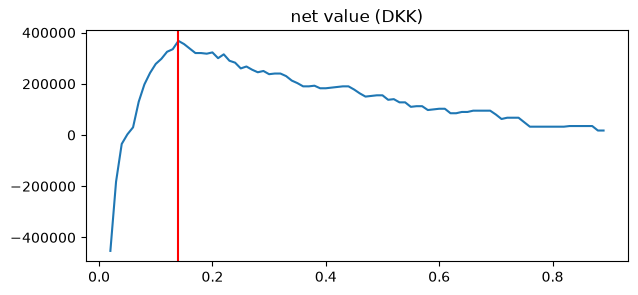

false alarm at 10,000 DKK: best cut-off 0.66, contacts 10


In [11]:
def value(df, cut, worry=COST_WORRY, helps=HELPS):
    b = boxes(df, cut)
    return b["TP"] * helps * COST_LEAVE - b["contacted"] * COST_TALK - b["FP"] * worry
cuts = np.round(np.arange(0.02, 0.9, 0.01), 2)
values = pd.Series([value(val, c) for c in cuts], index=cuts)
best = values.idxmax()
print(f"best cut-off {best} · contacts {boxes(val, best)['contacted']} · break-even {(COST_TALK+COST_WORRY)/(HELPS*COST_LEAVE+COST_WORRY):.3f}")
values.plot(figsize=(7, 3), title="net value (DKK)"); plt.axvline(best, color="red"); plt.show()
alt = pd.Series([value(val, c, worry=10_000) for c in cuts], index=cuts).idxmax()
print(f"false alarm at 10,000 DKK: best cut-off {alt}, contacts {boxes(val, alt)['contacted']}")

*Your answer:* With these assumptions the best cut-off is about **0.14** (the formula's break-even is 0.125), and the office
would contact **about 150 students**, far more than 40. If a false alarm is worth 10,000 DKK, the best rule contacts
only the few highest risks (about 10). If a conversation helps only 10 %, the cut-off rises too. The numbers are policy
choices, not facts: what a worried student "costs" should be decided by the university with students and advisers,
not by the data scientist, and written down.

---
## 7 · Only 40 conversations

The office can talk to **40** students at week 6. With a fixed capacity the rule becomes: **talk to the 40 with the
highest risk**. How many of the 40 were really at risk (**precision at 40**)? How many of all students who left were
among them (**recall at 40**)?

✏️ **Your turn.** Compute precision and recall at 40. How many conversations would you need to reach half of the students who leave? What would a fourth adviser (about 13 more conversations) buy?

<details><summary>Hint</summary>

`top = val.nlargest(40, 'risk')`; precision = `top['left'].mean()`; recall = `top['left'].sum() / val['left'].sum()`. Try other numbers instead of 40.
</details>

In [12]:
for k in [40, 53, 100]:
    top = val.nlargest(k, "risk")
    print(f"top {k}: precision {top['left'].mean():.0%} · recall {top['left'].sum() / val['left'].sum():.0%}")
reached = val.sort_values("risk", ascending=False)["left"].cumsum()
print("conversations needed to reach half of the leavers:", int((reached.values >= val["left"].sum() / 2).argmax()) + 1)

top 40: precision 35% · recall 22%
top 53: precision 34% · recall 28%


top 100: precision 29% · recall 45%
conversations needed to reach half of the leavers: 122


*Your answer:* Top 40: precision about 35 % (14 of the 40 really leave), recall about 22 % (14 of 65). Reaching half of the
leavers takes about 120 conversations. A fourth adviser (53 conversations) buys about 4 more students reached,
and at 60,000 DKK × 30 % help that is still worth it under our assumptions (the cost cut-off said ~150 contacts pay off).

---
## 8 · Fair to whom? ⚖️

About a fifth of the students are international. Compare the mistakes **per group** for the top-40 rule.

✏️ **Your turn.** For international and domestic students: the share who really leave, the average predicted risk, and the recall of the top-40 rule. Does the model get both groups right? Then compare how often each group logs in. Is a login the same signal for everyone? What would you tell the university?

<details><summary>Hint</summary>

Mark the top 40 first: `val['top40'] = val['risk'].rank(ascending=False) <= 40`. Then `val.groupby('international')[['left', 'risk']].mean()`; recall per group = among the students who left, the share with `top40`: `val[val['left'] == 1].groupby('international')['top40'].mean()`. Logins: `history.groupby('international')['logins_total'].mean()`.
</details>

In [13]:
val["top40"] = val["risk"].rank(ascending=False) <= 40
print(val.groupby("international")[["left", "risk"]].mean().round(3))
print("recall per group:", val[val["left"] == 1].groupby("international")["top40"].mean().round(2).to_dict())
print(history.groupby("international")["logins_total"].mean().round(1))

                left   risk
international              
0              0.069  0.088
1              0.070  0.072
recall per group: {0: 0.24, 1: 0.14}
international
0    36.4
1    23.6
Name: logins_total, dtype: float64


*Your answer:* Both groups leave equally often (7 %), but the model gives international students a lower average risk (7.2 % vs
8.8 %), and the top-40 rule reaches **14 % of the international leavers against 24 % of the domestic ones**.
International students log in far less (24 vs 36 logins by week 6) while handing in as much and scoring as well: they
use other channels. So a login is not the same signal for everyone. To the university: check recall per group before
use, prefer signals that mean the same for everyone (submissions, quizzes), and decide openly which fairness goal
to aim for (equal recall, or scores that mean the same in both groups; both cannot hold at once).

---
## 9 · Store the model

The app needs your model as files. Do it the way the hotel notebook (session 10) does in section 9, *Storing the model properly*: the
**portable copy** (`preprocess.json` + `booster.json`) loads in the app with any Python version, which a pickle does
not. The hotel app's `portable.py` does both the saving and the loading, for a pipeline built like the one in step 4.

✏️ **Your turn.** Save your XGBoost pipeline into a folder `model`, load it back with `portable.Model`, and check that it gives the same predictions. Download the folder as a zip. You will put it into your app's repository.

<details><summary>Hint</summary>

```python
import urllib.request, shutil
urllib.request.urlretrieve("https://raw.githubusercontent.com/aaubs/tonights-front-desk/main/portable.py", "portable.py")
import portable
os.makedirs("model", exist_ok=True)
portable.export(booster, "model")
back = portable.Model("model").predict_proba(val)
print(np.allclose(back, booster.predict_proba(val[features])[:, 1], atol=1e-5))
shutil.make_archive("model", "zip", "model")   # then download model.zip (Colab: the folder icon on the left)
```
</details>

In [14]:
import urllib.request, shutil
urllib.request.urlretrieve("https://raw.githubusercontent.com/aaubs/tonights-front-desk/main/portable.py", "portable.py")
import portable
os.makedirs("model", exist_ok=True)
portable.export(booster, "model")
back = portable.Model("model").predict_proba(val)
print("same predictions:", np.allclose(back, booster.predict_proba(val[features])[:, 1], atol=1e-5))
shutil.make_archive("model", "zip", "model")

same predictions: True


'/Users/roman/Desktop/10_Semesters/2026-E26/Teaching/BDS26_S2_3/assignment-study-office/answers/run/model.zip'

---
## 10 · This week's list

Now use the model the way the office would: on the 2026 students at the end of week 6.

✏️ **Your turn.** Predict the risk for every student in `new`, and show the 40 students the office should talk to this week. Would you send all 40 the same message? Is there anyone you would *not* contact?

<details><summary>Hint</summary>

`new['risk'] = booster.predict_proba(new[features])[:, 1]`, then `new.nlargest(40, 'risk')`.
</details>

In [15]:
new["risk"] = portable.Model("model").predict_proba(new)
new.nlargest(40, "risk")[["student_id", "programme", "international", "logins_last3", "missed_last3", "risk"]].round(3)

,student_id,programme,international,logins_last3,missed_last3,risk
234,S260271,Communication & Digital Media,0,6.0,3.0,0.923
243,S260281,Business Administration,0,8.0,2.0,0.887
336,S260391,Communication & Digital Media,1,7.0,1.0,0.880
566,S260648,Tourism,0,3.0,3.0,0.846
398,S260458,Communication & Digital Media,0,0.0,1.0,0.692
461,S260529,Business Administration,0,6.0,2.0,0.630
290,S260335,Sustainable Biotechnology,0,16.0,1.0,0.617
359,S260417,Business Administration,0,7.0,2.0,0.562
193,S260223,Social Work,0,7.0,2.0,0.561
610,S260696,Sustainable Biotechnology,0,6.0,3.0,0.536


*Your answer:* The 40 are mostly students with few recent logins and missed assignments. Not all the same message: a student who
owes fees needs help with money, one who has stopped logging in needs a first friendly contact, not a warning. Someone
I would not contact without looking: a student high on the list only because of little platform use but good
submissions and quizzes (often international). A person should read the list before anyone is contacted.

---
## 11 · Build the app 🛠️

Now build a Streamlit app for someone at the study office who is **not** a data scientist. Use the hotel app as your
template: [github.com/aaubs/tonights-front-desk](https://github.com/aaubs/tonights-front-desk) (`app.py`, `portable.py`,
`requirements.txt`, `model/`).

Your app should at least show:

1. **This week's list**: the 2026 students, ranked by risk, with the top 40 marked.
2. **The mistakes of a rule**: a slider (cut-off, or number of conversations) and, on the 2025 cohort, the four boxes
   in plain words ("12 students reached in time, 28 worried for nothing, 30 missed"), precision and recall.
3. **Per group**: the same numbers for international and domestic students.
4. **One thing of your own** that would help the office decide (for example the costs from step 6 as inputs, or why
   a student is on the list).

The app can read the data straight from GitHub, like this notebook (`URL + "new_week6.csv"`).

**Deploy:** create a public GitHub repository with `app.py`, `portable.py`, `requirements.txt` (`streamlit`,
`pandas`, `xgboost-cpu`, no version numbers) and your `model/` folder; then on
[share.streamlit.io](https://share.streamlit.io): *Create app* → your repository → `app.py`.